# Lab 2 - EDA và Làm sạch dữ liệu BigMart (Chuẩn Anti-Data Leakage)
Nguồn: https://www.kaggle.com/datasets/yasserh/bigmartsalesdataset

**Bài toán:** Dự đoán doanh số `Item_Outlet_Sales` của sản phẩm tại từng cửa hàng từ thuộc tính sản phẩm và cửa hàng (Tabular Regression).

### Trình tự thực hiện EDA & Xử lý cục bộ:
1. **Khám phá cấu trúc dữ liệu thô (Raw Data Overview)**: Kiểm tra cấu trúc, kiểu dữ liệu, các giá trị khuyết và phân bố đặc trưng ban đầu.
2. **Kiểm tra dữ liệu khuyết & bất thường**: Đánh giá tỷ lệ khuyết của `Item_Weight`, `Outlet_Size` và giá trị 0 của `Item_Visibility`.
3. **Trực quan hóa Khám phá Dữ liệu**: Phân tích hình thái biến mục tiêu, tương quan giá - doanh số, phân bố loại cửa hàng & loại sản phẩm.
4. **Tổng kết nhận xét EDA & Đề xuất phương án**: Rút ra insight từ dữ liệu thô để thiết kế quy trình xử lý dữ liệu.
5. **Tiền xử lý dữ liệu cục bộ không trạng thái (Stateless Cleaning)**: Chuẩn hóa chuỗi, sửa nhãn rác `Item_Fat_Content`, tạo đặc trưng tuổi cửa hàng `Outlet_Age`, cờ chỉ báo missing, xuất file sạch ban đầu `data/tu_data/processed/bigmart_clean.csv` phục vụ cho mô-đun nạp dữ liệu `src/data_loader.py`.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
while not (ROOT / "data/tu_data/raw/bigmart.csv").is_file():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Hãy mở notebook bên trong thư mục GR_05_Lab_2.")
    ROOT = ROOT.parent

output = ROOT / "outputs"
processed = ROOT / "data/tu_data/processed"
figures = output / "figures"
for folder in [output, processed, figures]:
    folder.mkdir(parents=True, exist_ok=True)

plt.rcParams["font.family"] = "DejaVu Sans"
print("Thư mục gốc của dự án:", ROOT)

Thư mục gốc của dự án: C:\Users\Nguyen Thanh Huy\Documents\Machine_Learning\GR_05_Lab_2


## 1. Đọc và khám phá cấu trúc dữ liệu thô (Raw Data Overview)
Một dòng biểu diễn một sản phẩm tại một cửa hàng. Giữ mã định danh ở dạng chuỗi (`string`).
Kiểm tra số lượng mẫu, số lượng sản phẩm duy nhất, số lượng cửa hàng và kiểm tra trùng lặp.

In [2]:
raw = pd.read_csv(ROOT / "data/tu_data/raw/bigmart.csv",
                  dtype={"Item_Identifier": "string", "Outlet_Identifier": "string"})
print("Số dòng, số cột:", raw.shape)
print("Sản phẩm duy nhất:", raw["Item_Identifier"].nunique())
print("Cửa hàng duy nhất:", raw["Outlet_Identifier"].nunique())
print("Trùng toàn bộ dòng:", raw.duplicated().sum())
print("Trùng cặp sản phẩm/cửa hàng:", raw.duplicated(["Item_Identifier", "Outlet_Identifier"]).sum())
print("\nKiểu dữ liệu:")
print(raw.dtypes.to_string())
print("\nPhân bố ban đầu của Item_Fat_Content (chứa nhãn rác LF, low fat, reg):")
print(raw["Item_Fat_Content"].value_counts().to_string())
raw.head()

Số dòng, số cột: (8523, 12)
Sản phẩm duy nhất: 1559
Cửa hàng duy nhất: 10
Trùng toàn bộ dòng: 0
Trùng cặp sản phẩm/cửa hàng: 0

Kiểu dữ liệu:
Item_Identifier              string[python]
Item_Weight                         float64
Item_Fat_Content                     object
Item_Visibility                     float64
Item_Type                            object
Item_MRP                            float64
Outlet_Identifier            string[python]
Outlet_Establishment_Year             int64
Outlet_Size                          object
Outlet_Location_Type                 object
Outlet_Type                          object
Item_Outlet_Sales                   float64

Phân bố ban đầu của Item_Fat_Content (chứa nhãn rác LF, low fat, reg):
Item_Fat_Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


## 2. Kiểm tra dữ liệu khuyết và giá trị bất thường trên dữ liệu thô
Kiểm tra tỷ lệ missing trên từng cột, kiểm tra biến mục tiêu `Item_Outlet_Sales` (có âm, bằng 0 hoặc thiếu hay không), và kiểm tra các giá trị đặc biệt như `Item_Visibility = 0`.

In [3]:
missing_raw = pd.DataFrame({"Số thiếu": raw.isna().sum(),
                            "Tỷ lệ thiếu (%)": raw.isna().mean() * 100})
print(missing_raw.round(2).to_string())

target = raw["Item_Outlet_Sales"]
print("\n[Kiểm tra biến mục tiêu Item_Outlet_Sales]")
print(" - Số lượng thiếu:", target.isna().sum())
print(" - Số lượng bằng 0:", target.eq(0).sum())
print(" - Số lượng âm:", target.lt(0).sum())
print(" - Giá trị nhỏ nhất / lớn nhất:", target.min(), "/", target.max())
print(" - Item_Visibility bằng 0:", raw["Item_Visibility"].eq(0).sum())

print("\nThống kê mô tả các cột số thô:")
print(raw.select_dtypes(include="number").describe().round(2).to_string())
missing_raw.to_csv(output / "missing_raw.csv", encoding="utf-8-sig", index_label="Cột")

                           Số thiếu  Tỷ lệ thiếu (%)
Item_Identifier                   0             0.00
Item_Weight                    1463            17.17
Item_Fat_Content                  0             0.00
Item_Visibility                   0             0.00
Item_Type                         0             0.00
Item_MRP                          0             0.00
Outlet_Identifier                 0             0.00
Outlet_Establishment_Year         0             0.00
Outlet_Size                    2410            28.28
Outlet_Location_Type              0             0.00
Outlet_Type                       0             0.00
Item_Outlet_Sales                 0             0.00

[Kiểm tra biến mục tiêu Item_Outlet_Sales]
 - Số lượng thiếu: 0
 - Số lượng bằng 0: 0
 - Số lượng âm: 0
 - Giá trị nhỏ nhất / lớn nhất: 33.29 / 13086.9648
 - Item_Visibility bằng 0: 526

Thống kê mô tả các cột số thô:


       Item_Weight  Item_Visibility  Item_MRP  Outlet_Establishment_Year  Item_Outlet_Sales
count      7060.00          8523.00   8523.00                    8523.00            8523.00
mean         12.86             0.07    140.99                    1997.83            2181.29
std           4.64             0.05     62.28                       8.37            1706.50
min           4.56             0.00     31.29                    1985.00              33.29
25%           8.77             0.03     93.83                    1987.00             834.25
50%          12.60             0.05    143.01                    1999.00            1794.33
75%          16.85             0.09    185.64                    2004.00            3101.30
max          21.35             0.33    266.89                    2009.00           13086.96


## 3. Trực quan hóa Khám phá Dữ liệu (Exploratory Data Visualizations)
Vẽ biểu đồ phân bố biến mục tiêu, dữ liệu thiếu, doanh số theo loại cửa hàng, quan hệ giá niêm yết - doanh số và hồ sơ doanh số theo danh mục sản phẩm trực tiếp từ dữ liệu thô.

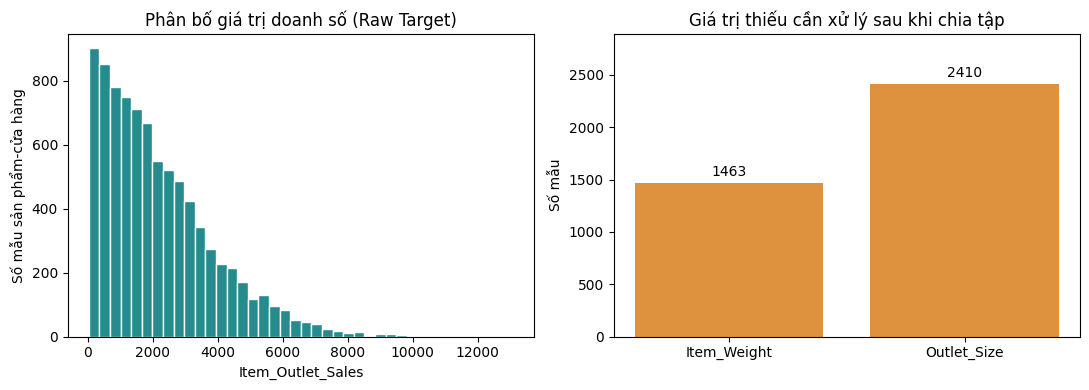

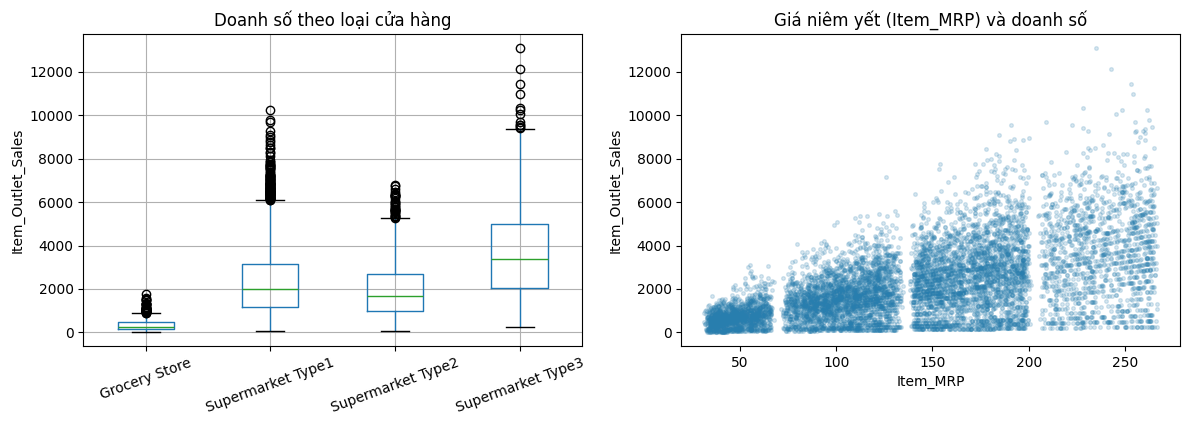

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(raw["Item_Outlet_Sales"], bins=40, color="#258b8e", edgecolor="white")
axes[0].set_title("Phân bố giá trị doanh số (Raw Target)")
axes[0].set_xlabel("Item_Outlet_Sales")
axes[0].set_ylabel("Số mẫu sản phẩm-cửa hàng")

missing_nonzero = missing_raw.loc[missing_raw["Số thiếu"] > 0, "Số thiếu"]
bars = axes[1].bar(missing_nonzero.index, missing_nonzero.values, color="#df923e")
axes[1].bar_label(bars, padding=3)
axes[1].set_title("Giá trị thiếu cần xử lý sau khi chia tập")
axes[1].set_ylabel("Số mẫu")
axes[1].set_ylim(0, max(missing_nonzero.values) * 1.2)
fig.tight_layout()
fig.savefig(figures / "bigmart_distribution_missing.png", dpi=180, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
raw.boxplot(column="Item_Outlet_Sales", by="Outlet_Type", ax=axes[0], rot=20)
axes[0].set_title("Doanh số theo loại cửa hàng")
axes[0].set_xlabel("")
axes[0].set_ylabel("Item_Outlet_Sales")
axes[1].scatter(raw["Item_MRP"], raw["Item_Outlet_Sales"], s=7, alpha=0.18, color="#287eae")
axes[1].set_title("Giá niêm yết (Item_MRP) và doanh số")
axes[1].set_xlabel("Item_MRP")
axes[1].set_ylabel("Item_Outlet_Sales")
fig.suptitle("")
fig.tight_layout()
fig.savefig(figures / "bigmart_outlet_price.png", dpi=180, bbox_inches="tight")
plt.show()

### Khám phá phân bố theo danh mục sản phẩm (Item_Type Profile)
Tính toán số lượng mẫu và mức doanh số trung bình/trung vị của từng loại sản phẩm.

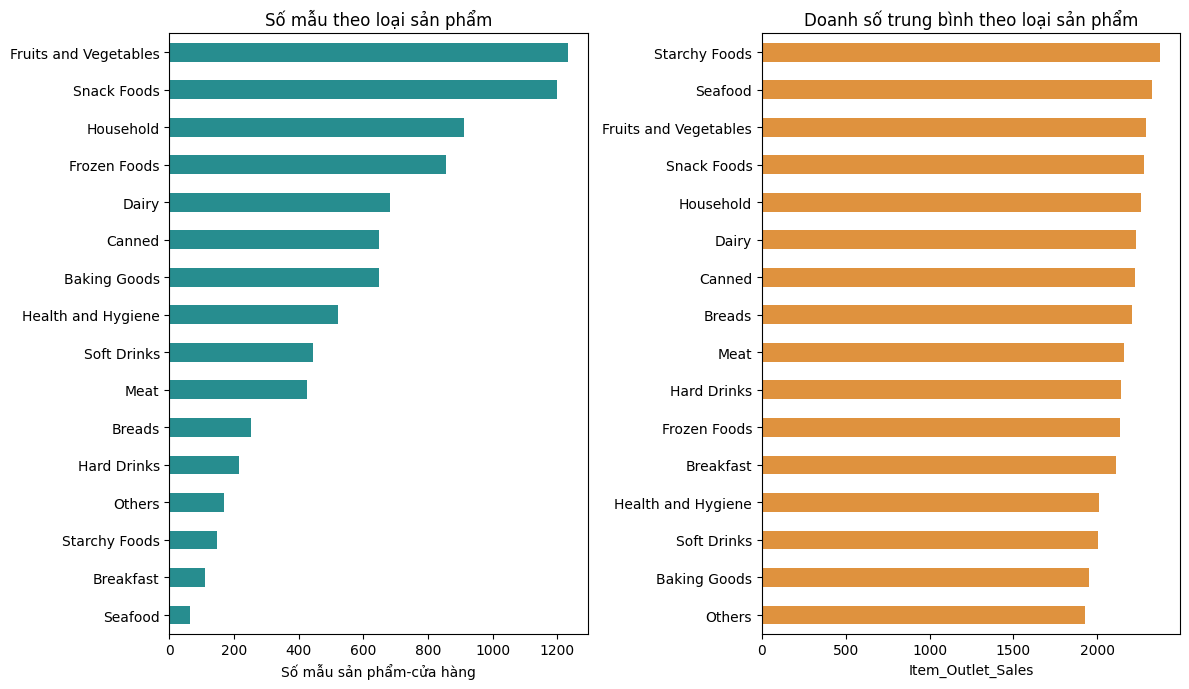

In [5]:
category_profile = raw.groupby("Item_Type")["Item_Outlet_Sales"].agg(["count", "mean", "median"])
category_profile.to_csv(output / "category_profile.csv", encoding="utf-8-sig")

fig, axes = plt.subplots(1, 2, figsize=(12, 7))
category_profile["count"].sort_values().plot.barh(ax=axes[0], color="#278d8f")
axes[0].set_title("Số mẫu theo loại sản phẩm")
axes[0].set_xlabel("Số mẫu sản phẩm-cửa hàng")
axes[0].set_ylabel("")

category_profile["mean"].sort_values().plot.barh(ax=axes[1], color="#df923e")
axes[1].set_title("Doanh số trung bình theo loại sản phẩm")
axes[1].set_xlabel("Item_Outlet_Sales")
axes[1].set_ylabel("")
fig.tight_layout()
fig.savefig(figures / "bigmart_category_profiles.png", dpi=180, bbox_inches="tight")
plt.show()

## 4. Tổng kết nhận xét EDA & Đề xuất phương án tiền xử lý
1. **Doanh số (`Item_Outlet_Sales`)**: Phân bố lệch phải (right-skewed), tập trung ở dải giá trị thấp/trung bình và có một số mẫu doanh số rất cao (hợp lệ trong bán lẻ, không tự ý cắt bỏ).
2. **Dữ liệu khuyết**: Cột `Item_Weight` thiếu ~17.17% và `Outlet_Size` thiếu ~28.28%.
3. **Giá trị rác**: Cột `Item_Fat_Content` chứa các nhãn viết tắt không đồng nhất: `LF`, `low fat` (Low Fat), `reg` (Regular).
4. **Đặc trưng thời gian**: `Outlet_Establishment_Year` cần được chuyển đổi thành tuổi hoạt động của cửa hàng (`Outlet_Age = 2026 - Outlet_Establishment_Year`).
5. **YÊU CẦU TỐI THƯỢNG (ANTI-DATA LEAKAGE)**:
   - Tuyệt đối không tính toán giá trị điền khuyết (mean, median, mode) hay chuẩn hóa/mã hóa trên toàn bộ dữ liệu trước khi chia.
   - **Bắt buộc phân chia tập dữ liệu thành Train (70%), Validation (15%), Test (15%) TRƯỚC KHI thực hiện các phép tiền xử lý có trạng thái!**

## 5. Tiền xử lý dữ liệu cục bộ không trạng thái (Stateless Cleaning)
Các phép biến đổi logic cố định độc lập (không phụ thuộc vào phân phối dữ liệu):
- Chuẩn hóa kiểu chuỗi và loại bỏ khoảng trắng thừa.
- Chuẩn hóa nhãn `Item_Fat_Content` ('LF', 'low fat' -> 'Low Fat'; 'reg' -> 'Regular').
- Tạo cột `Outlet_Age = 2026 - Outlet_Establishment_Year`.
- Tạo các cờ chỉ báo chất lượng: `Item_Weight_Missing`, `Outlet_Size_Missing`, `Item_Visibility_Zero`.
- Kiểm chứng tính toàn vẹn và xuất dữ liệu sạch ra `data/tu_data/processed/bigmart_clean.csv` làm điểm chuyển giao sang ML Pipeline.

In [7]:
clean = raw.copy()
clean.insert(0, "source_row", raw.index)

# Chuẩn hóa chuỗi và loại bỏ khoảng trắng thừa
text_columns = clean.select_dtypes(include=["object", "string"]).columns
for column in text_columns:
    clean[column] = clean[column].astype("string").str.strip()
    clean.loc[clean[column] == "", column] = pd.NA

# Chuẩn hóa nhãn Item_Fat_Content
fat_before = clean["Item_Fat_Content"].copy()
fat_names = {"low fat": "Low Fat", "lowfat": "Low Fat", "lf": "Low Fat",
             "regular": "Regular", "reg": "Regular"}
clean["Item_Fat_Content"] = clean["Item_Fat_Content"].str.lower().map(fat_names)
if clean["Item_Fat_Content"].isna().any():
    raise ValueError("Có nhãn hàm lượng chất béo chưa xác định!")
changed_fat = int(fat_before.ne(clean["Item_Fat_Content"]).sum())

# Feature Engineering: Tuổi cửa hàng & Cờ chất lượng
clean["Outlet_Age"] = 2026 - clean["Outlet_Establishment_Year"]
clean["Item_Weight_Missing"] = clean["Item_Weight"].isna().astype(int)
clean["Outlet_Size_Missing"] = clean["Outlet_Size"].isna().astype(int)
clean["Item_Visibility_Zero"] = clean["Item_Visibility"].eq(0).astype(int)

# Kiểm chứng tính toàn vẹn
required = ["Item_Identifier", "Outlet_Identifier", "Item_Outlet_Sales", "Item_MRP", "Item_Type"]
assert clean[required].notna().all().all()
assert clean["Item_Outlet_Sales"].gt(0).all()
assert clean["Item_MRP"].gt(0).all()
assert clean["Item_Weight"].dropna().gt(0).all()
assert clean["Item_Visibility"].between(0, 1).all()
assert clean["source_row"].is_unique
assert set(clean["Item_Fat_Content"]) == {"Low Fat", "Regular"}

# Lưu file clean
clean.to_csv(processed / "bigmart_clean.csv", index=False, encoding="utf-8-sig")

missing = pd.DataFrame({"Trước": raw.isna().sum(), "Sau chuẩn hóa": clean[raw.columns].isna().sum()})
missing.to_csv(output / "missing_before_after.csv", encoding="utf-8-sig", index_label="Cột")

summary = pd.Series({
    "raw_rows": len(raw), "raw_columns": raw.shape[1],
    "clean_rows": len(clean), "duplicates_removed": 0,
    "products": clean["Item_Identifier"].nunique(),
    "outlets": clean["Outlet_Identifier"].nunique(),
    "fat_labels_normalized": changed_fat,
    "missing_item_weight": int(clean["Item_Weight"].isna().sum()),
    "missing_outlet_size": int(clean["Outlet_Size"].isna().sum()),
    "zero_visibility": int(clean["Item_Visibility"].eq(0).sum()),
    "zero_target": int(clean["Item_Outlet_Sales"].eq(0).sum()),
    "negative_target": int(clean["Item_Outlet_Sales"].lt(0).sum())
}, name="value")
summary.to_csv(output / "cleaning_summary.csv", index_label="metric")

print(f"Số nhãn Item_Fat_Content được chuẩn hóa: {changed_fat}")
print("Phân bố Item_Fat_Content sau chuẩn hóa:")
print(clean["Item_Fat_Content"].value_counts().to_string())
print("\nTóm tắt trạng thái dữ liệu:")
print(summary.to_string())

Số nhãn Item_Fat_Content được chuẩn hóa: 545
Phân bố Item_Fat_Content sau chuẩn hóa:
Item_Fat_Content
Low Fat    5517
Regular    3006

Tóm tắt trạng thái dữ liệu:
raw_rows                 8523
raw_columns                12
clean_rows               8523
duplicates_removed          0
products                 1559
outlets                    10
fat_labels_normalized     545
missing_item_weight      1463
missing_outlet_size      2410
zero_visibility           526
zero_target                 0
negative_target             0
